# Chapitre 14 - Exercices 14.1 à 14.6

Pondération des distances, algorithme EM et K-means, règles d'association généralisées par
arbres et PRIM, cartes auto-organisatrices.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch14_non_supervise as ns
set_style()

## Exercice 14.1 : Poids dans une distance euclidienne

**Énoncé.** On définit la distance euclidienne pondérée, de poids $w_l > 0$,

$$d_e^{(w)}(x_i, x_{i'}) = \frac{\sum_{l=1}^p w_l (x_{il} - x_{i'l})^2}{\sum_{l=1}^p w_l}.$$

Montrer que $d_e^{(w)}(x_i, x_{i'}) = d_e(z_i, z_{i'}) = \sum_{l=1}^p (z_{il} - z_{i'l})^2$
(éq. (14.112)) avec $z_{il} = x_{il}\,\big(w_l / \sum_{l'} w_{l'}\big)^{1/2}$ (éq. (14.113)) :
la distance pondérée sur $x$ est la distance usuelle sur des variables $z$ remises à l'échelle.

### Solution

Notons $W = \sum_{l'} w_{l'} > 0$ et $c_l = (w_l/W)^{1/2}$, de sorte que $z_{il} = c_l\, x_{il}$.
Pour chaque coordonnée $l$, par linéarité,

$$z_{il} - z_{i'l} = c_l\,(x_{il} - x_{i'l}) \quad\Longrightarrow\quad
(z_{il} - z_{i'l})^2 = c_l^2 (x_{il} - x_{i'l})^2 = \frac{w_l}{W}(x_{il} - x_{i'l})^2 .$$

En sommant sur $l$ :
$\sum_l (z_{il} - z_{i'l})^2 = \frac{1}{W}\sum_l w_l (x_{il} - x_{i'l})^2 = d_e^{(w)}(x_i, x_{i'})$.
$\square$

> **Conséquence pratique.** Tout algorithme fondé sur la distance euclidienne (K-means,
> classification hiérarchique…) appliqué avec des poids $w_l$ équivaut à l'algorithme
> **non pondéré** appliqué aux variables $z_l = c_l x_l$ : pondérer, c'est changer d'échelle.
> Par exemple les poids $w_l = 1/(2\,\mathrm{var}_l)$ correspondent à la standardisation.

### Vérification numérique

In [2]:
rng = np.random.RandomState(0)
X = rng.normal(size=(6, 4))
w = np.array([1.0, 4.0, 0.5, 2.0])
d_w = (w * (X[:, None, :] - X[None, :, :]) ** 2).sum(-1) / w.sum()
Z = X * np.sqrt(w / w.sum())
d_z = ns.distances_carrees(Z)
print("écart maximal entre les deux matrices : %.2e" % np.abs(d_w - d_z).max())

écart maximal entre les deux matrices : 1.78e-15


Les K-means « pondérés » (affectation selon $d_e^{(w)}$, centres = moyennes) donnent donc la
même partition que les K-means ordinaires sur $Z$ :

In [3]:
X2 = np.vstack([rng.normal(m, 1, size=(40, 2)) for m in ((0, 0), (0, 4), (6, 2))])
w2 = np.array([1.0, 9.0])
Z2 = X2 * np.sqrt(w2 / w2.sum())
lab_z, C_z, _ = ns.kmeans(Z2, 3, rng=np.random.RandomState(0))
C = C_z / np.sqrt(w2 / w2.sum())          # centres ramenés dans l'échelle de x
lab_w = ((w2 * (X2[:, None, :] - C[None]) ** 2).sum(-1)).argmin(1)
print("Partitions identiques :", np.array_equal(lab_z, lab_w))

Partitions identiques : True


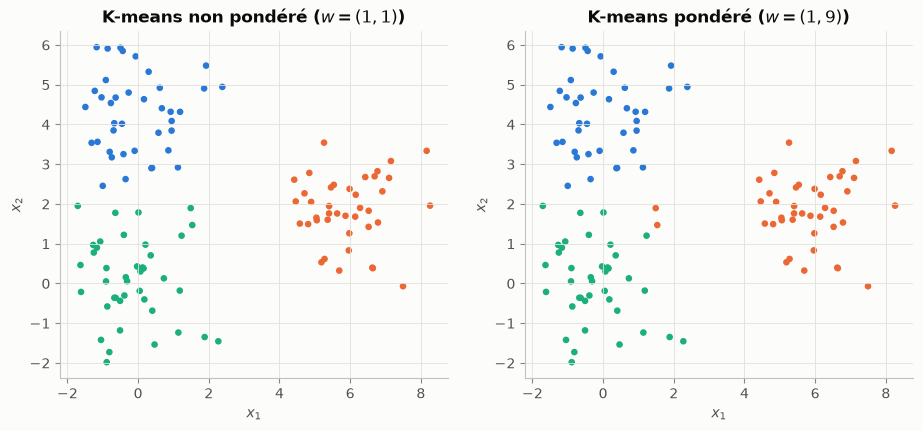

In [4]:
lab_x = ns.kmeans(X2, 3, rng=np.random.RandomState(0))[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, lab, titre in ((axes[0], lab_x, "K-means non pondéré ($w = (1, 1)$)"),
                       (axes[1], lab_w, "K-means pondéré ($w = (1, 9)$)")):
    ax.scatter(*X2.T, c=[COLORS[k] for k in lab], s=14)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(titre)
plt.show()

Le poids 9 sur $x_2$ revient à étirer l'axe vertical d'un facteur 3 : la partition change.

> **À retenir.** Pondérer la distance euclidienne équivaut à multiplier chaque variable par la
> racine de son poids normalisé ; le choix des poids est un choix d'échelle des variables.

## Exercice 14.2 : Algorithme EM pour un mélange gaussien isotrope et K-means

**Énoncé.** On considère le mélange $g(x) = \sum_{k=1}^K \pi_k g_k(x)$ (14.114) avec
$g_k = \mathcal{N}(\mu_k, \sigma^2 \mathbf{I})$ ($\mathbf{I}$ : identité $p \times p$), $\pi_k \ge 0$,
$\sum_k \pi_k = 1$, les paramètres $\{\mu_k, \pi_k\}$ et $\sigma^2$ étant inconnus. On observe
$x_1, \dots, x_N$ i.i.d. de densité $g$.

1. Écrire la log-vraisemblance.
2. Dériver un algorithme EM pour l'estimateur du maximum de vraisemblance.
3. Montrer que si $\sigma$ est connu et tend vers 0, cet algorithme coïncide en un sens avec les
   K-means.

### Rappels : densité gaussienne isotrope

La densité de $\mathcal{N}(\mu, \sigma^2\mathbf{I})$ dans $\mathbb{R}^p$ est

$$\phi_\sigma(x; \mu) = (2\pi\sigma^2)^{-p/2} \exp\Big(-\frac{\|x - \mu\|^2}{2\sigma^2}\Big).$$